# COMP1818 – AI Facial Recognition and Biometric Authentication

## 1. Introduction

This notebook investigates the performance of AdaFace IR18, a pretrained deep learning model for face verification.

The experiments evaluate the model across six benchmark datasets and investigate how changes in image brightness and Gaussian blur affect face verification performance.

The notebook also compares AdaFace IR18 against a simple majority-class baseline.

## 2. Environment Setup

This section prepares the Google Colab environment for the face verification experiments.

The AdaFace repository is cloned from GitHub, and the pretrained AdaFace IR18 model, trained on CASIA-WebFace, is downloaded.

Google Drive is mounted to access the benchmark datasets used for evaluation.

In [1]:
!git clone https://github.com/mk-minchul/AdaFace.git /content/AdaFace
%cd /content/AdaFace

Cloning into '/content/AdaFace'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 236 (delta 66), reused 56 (delta 56), pack-reused 129 (from 1)
Receiving objects: 100% (236/236), 38.95 MiB | 16.37 MiB/s, done.
Resolving deltas: 100% (88/88), done.
/content/AdaFace


In [2]:
!pip install -q gdown
!mkdir -p /content/AdaFace/pretrained

!gdown --fuzzy "https://drive.google.com/file/d/1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe/view?usp=sharing" -O /content/AdaFace/pretrained/adaface_ir18_casia.ckpt

Downloading...
From (original): https://drive.google.com/uc?id=1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe
From (redirected): https://drive.google.com/uc?id=1BURBDplf2bXpmwOL1WVzqtaVmQl9NpPe&confirm=t&uuid=cbd9e440-1a4d-40d5-98d0-cfbb37799757
To: /content/AdaFace/pretrained/adaface_ir18_casia.ckpt
100% 118M/118M [00:02<00:00, 45.9MB/s]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Dataset Preparation

Six benchmark datasets are used to evaluate the pretrained AdaFace IR18 model: LFW, CFP-FF, CFP-FP, AgeDB-30, CALFW and CPLFW.

The datasets contain pairs of facial images labelled as either belonging to the same person or different people.

The dataset files are extracted from Google Drive and checked before being used in the experiments.

In [4]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/faces_webface_112x112.zip"
extract_path = "/content/data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")
print("Extracted folders:", os.listdir(extract_path))

Extraction complete!
Extracted folders: ['faces_webface_112x112']


## 4. Model Loading and Face Embeddings

This section loads the pretrained AdaFace IR18 model and prepares it for face verification.

The model is configured to use the downloaded CASIA-WebFace checkpoint and runs on a GPU when available.

A face embedding function is defined to convert facial images into 512-dimensional numerical representations. These embeddings are subsequently used to calculate similarity between pairs of faces.

In [5]:
import sys
sys.path.insert(0, "/content/AdaFace")

import inference
from inference import load_pretrained_model

inference.adaface_models["ir_18"] = (
    "/content/AdaFace/pretrained/adaface_ir18_casia.ckpt"
)

print("IR18 checkpoint configured successfully!")

/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:287: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if align_type is 'cv2_affine':
/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:290: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif align_type is 'affine':


IR18 checkpoint configured successfully!


In [6]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = load_pretrained_model("ir_18")
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Model: AdaFace IR18 (CASIA-WebFace)")

Model loaded successfully!
Device: cuda
Model: AdaFace IR18 (CASIA-WebFace)


In [7]:
import cv2
import numpy as np
import torch

def get_embeddings(model, images, batch_size=128):
    embeddings = []

    model.eval()

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch_images = images[i:i + batch_size]

            processed = []

            for image_bytes in batch_images:
                image = cv2.imdecode(
                    np.frombuffer(image_bytes, dtype=np.uint8),
                    cv2.IMREAD_COLOR
                )

                if image is None:
                    raise ValueError("Could not decode image")

                image = cv2.resize(image, (112, 112))
                image = image.astype(np.float32) / 127.5 - 1.0
                image = torch.from_numpy(image).permute(2, 0, 1)

                processed.append(image)

            batch = torch.stack(processed).to(device)

            features, _ = model(batch)
            embeddings.append(features.cpu())

    return torch.cat(embeddings, dim=0)

print("Face embedding function ready!")

Face embedding function ready!


In [8]:
import pickle
import os

data_path = "/content/data/faces_webface_112x112"

lfw_path = os.path.join(data_path, "lfw.bin")

with open(lfw_path, "rb") as f:
    lfw_images, lfw_labels = pickle.load(f, encoding="bytes")

print("Images:", len(lfw_images))
print("Pairs:", len(lfw_labels))
print("Same-person pairs:", sum(lfw_labels))
print("Different-person pairs:", len(lfw_labels) - sum(lfw_labels))

Images: 12000
Pairs: 6000
Same-person pairs: 3000
Different-person pairs: 3000


In [9]:
lfw_embeddings = get_embeddings(
    model,
    lfw_images,
    batch_size=128
)

print("Embeddings generated successfully!")
print("Embedding shape:", lfw_embeddings.shape)

Embeddings generated successfully!
Embedding shape: torch.Size([12000, 512])


## 5. Face Verification and Evaluation

This section evaluates the face verification performance of AdaFace IR18 using the LFW dataset.

Face embeddings are normalised, and cosine similarity is calculated between pairs of facial images.

A 10-fold cross-validation procedure is used to measure verification accuracy and standard deviation. Additional evaluation metrics include Equal Error Rate (EER) and True Accept Rate (TAR) at a False Accept Rate (FAR) of 0.1%.

In [10]:
import torch.nn.functional as F
import numpy as np

# Normalise face embeddings
normalised = F.normalize(lfw_embeddings, p=2, dim=1)

# Separate embeddings into image pairs
image1 = normalised[0::2]
image2 = normalised[1::2]

# Calculate cosine similarity for each pair
lfw_scores = (image1 * image2).sum(dim=1).numpy()

# Convert labels into NumPy array
lfw_labels = np.array(lfw_labels, dtype=bool)

print("Total similarity scores:", len(lfw_scores))
print("Same-person mean similarity:", round(lfw_scores[lfw_labels].mean(), 4))
print("Different-person mean similarity:", round(lfw_scores[~lfw_labels].mean(), 4))

Total similarity scores: 6000
Same-person mean similarity: 0.5686
Different-person mean similarity: 0.0106


In [11]:
import numpy as np
from sklearn.metrics import roc_curve

def evaluate(scores, labels):
    scores = np.asarray(scores)
    labels = np.asarray(labels, dtype=bool)

    folds = np.array_split(np.arange(len(scores)), 10)
    thresholds = np.linspace(-1, 1, 400)

    fold_accuracies = []

    for test_idx in folds:
        train_idx = np.setdiff1d(np.arange(len(scores)), test_idx)

        train_scores = scores[train_idx]
        train_labels = labels[train_idx]

        train_accuracies = [
            np.mean((train_scores >= t) == train_labels)
            for t in thresholds
        ]

        best_threshold = thresholds[np.argmax(train_accuracies)]

        test_accuracy = np.mean(
            (scores[test_idx] >= best_threshold) == labels[test_idx]
        )

        fold_accuracies.append(test_accuracy)

    fpr, tpr, _ = roc_curve(labels, scores)
    fnr = 1 - tpr

    eer_index = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[eer_index] + fnr[eer_index]) / 2

    tar = np.interp(0.001, fpr, tpr)

    return {
        "accuracy": np.mean(fold_accuracies),
        "std": np.std(fold_accuracies),
        "fold_accuracies": fold_accuracies,
        "eer": eer,
        "tar": tar
    }

lfw_results = evaluate(lfw_scores, lfw_labels)

print("LFW Verification Results")
print("------------------------")
print(f"Accuracy: {lfw_results['accuracy'] * 100:.2f}%")
print(f"Standard deviation: {lfw_results['std'] * 100:.2f}%")
print(f"EER: {lfw_results['eer'] * 100:.2f}%")
print(f"TAR @ FAR 0.1%: {lfw_results['tar'] * 100:.2f}%")

LFW Verification Results
------------------------
Accuracy: 99.23%
Standard deviation: 0.40%
EER: 0.90%
TAR @ FAR 0.1%: 97.27%


## 6. Benchmark Dataset Comparison

This section evaluates AdaFace IR18 across six face verification benchmark datasets: LFW, CFP-FF, CFP-FP, AgeDB-30, CALFW and CPLFW.

The same face embedding extraction and evaluation procedures are applied to each dataset to compare verification performance.

The results are presented in a table and bar chart to identify differences in accuracy across the datasets, including those containing variations in facial pose and age.

In [12]:
import pandas as pd
import pickle
import torch.nn.functional as F

results = [{
    "Dataset": "LFW",
    "Accuracy (%)": lfw_results["accuracy"] * 100,
    "Std (%)": lfw_results["std"] * 100,
    "EER (%)": lfw_results["eer"] * 100,
    "TAR @ FAR 0.1%": lfw_results["tar"] * 100
}]

remaining_datasets = [
    ("CFP_FF", "cfp_ff.bin"),
    ("CFP_FP", "cfp_fp.bin"),
    ("AGEDB_30", "agedb_30.bin"),
    ("CALFW", "calfw.bin"),
    ("CPLFW", "cplfw.bin")
]

for name, filename in remaining_datasets:
    print(f"Evaluating {name}...")

    with open(os.path.join(data_path, filename), "rb") as f:
        images, labels = pickle.load(f, encoding="bytes")

    embeddings = get_embeddings(model, images, batch_size=128)
    embeddings = F.normalize(embeddings, p=2, dim=1)

    scores = (
        embeddings[0::2] * embeddings[1::2]
    ).sum(dim=1).numpy()

    metrics = evaluate(scores, labels)

    results.append({
        "Dataset": name,
        "Accuracy (%)": metrics["accuracy"] * 100,
        "Std (%)": metrics["std"] * 100,
        "EER (%)": metrics["eer"] * 100,
        "TAR @ FAR 0.1%": metrics["tar"] * 100
    })

df = pd.DataFrame(results)

display(df.round(2))

Evaluating CFP_FF...
Evaluating CFP_FP...
Evaluating AGEDB_30...
Evaluating CALFW...
Evaluating CPLFW...


,Dataset,Accuracy (%),Std (%),EER (%),TAR @ FAR 0.1%
0,LFW,99.23,0.40,0.90,97.27
1,CFP_FF,99.10,0.39,0.91,97.97
2,CFP_FP,91.90,1.43,8.77,71.14
3,AGEDB_30,91.95,1.73,7.87,52.97
4,CALFW,92.60,1.51,7.93,65.73
5,CPLFW,86.07,1.93,16.07,0.57


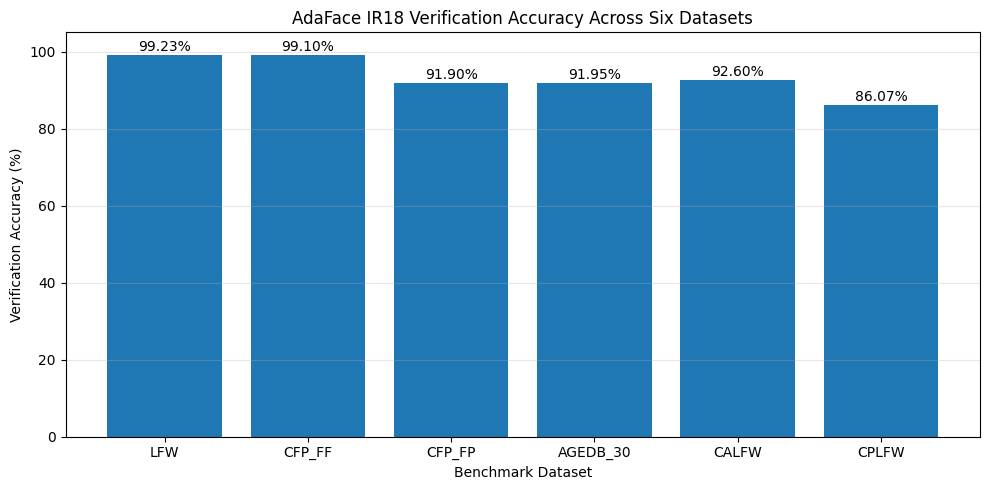

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    df["Dataset"],
    df["Accuracy (%)"]
)

plt.ylim(0, 105)
plt.xlabel("Benchmark Dataset")
plt.ylabel("Verification Accuracy (%)")
plt.title("AdaFace IR18 Verification Accuracy Across Six Datasets")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Robustness Experiments

This section investigates how changes in lighting conditions and image quality affect the performance of AdaFace IR18.

Two types of image transformations are examined: brightness adjustments and Gaussian blur.

The experiments use modified versions of LFW facial images to assess how robust the model is to different visual conditions.

### 7.1 Effect of Lighting Conditions

Brightness levels are adjusted to simulate darker and brighter lighting conditions. The resulting images are used to evaluate changes in face verification accuracy.

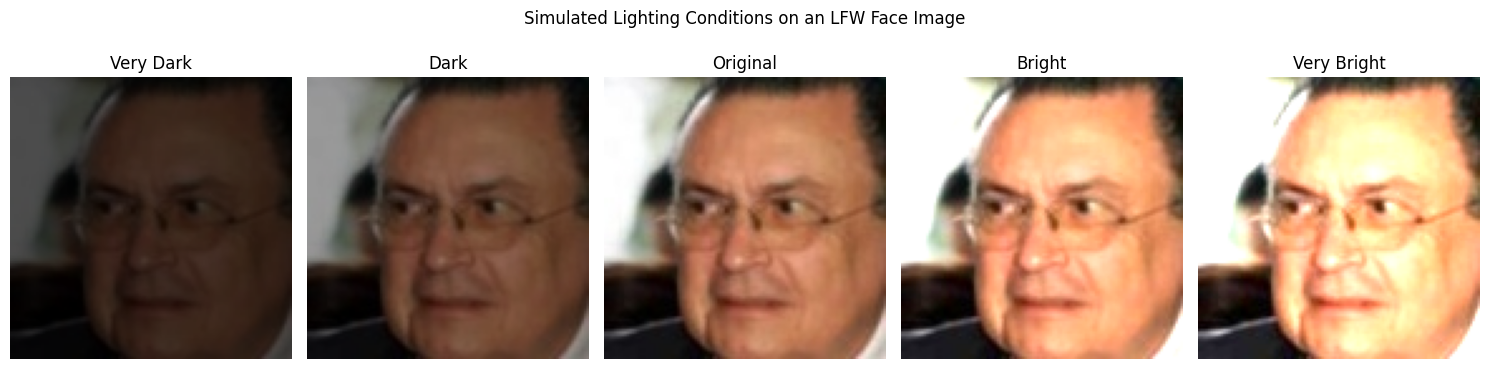

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Decode one image from LFW
image = cv2.imdecode(
    np.frombuffer(lfw_images[0], dtype=np.uint8),
    cv2.IMREAD_COLOR
)

# Create different lighting conditions
brightness_levels = {
    "Very Dark": 0.3,
    "Dark": 0.6,
    "Original": 1.0,
    "Bright": 1.4,
    "Very Bright": 1.8
}

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, (name, factor) in zip(axes, brightness_levels.items()):
    modified = np.clip(
        image.astype(np.float32) * factor,
        0,
        255
    ).astype(np.uint8)

    ax.imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Simulated Lighting Conditions on an LFW Face Image")
plt.tight_layout()
plt.show()

In [15]:
import cv2
import numpy as np
import torch.nn.functional as F

# Original reference images remain unchanged
reference_embeddings = F.normalize(
    lfw_embeddings[0::2], p=2, dim=1
)

# Second image of each verification pair
comparison_images = lfw_images[1::2]

lighting_results = []

for condition, factor in brightness_levels.items():
    print(f"Evaluating {condition}...")

    if factor == 1.0:
        comparison_embeddings = lfw_embeddings[1::2]
    else:
        modified_images = []

        for image_bytes in comparison_images:
            image = cv2.imdecode(
                np.frombuffer(image_bytes, dtype=np.uint8),
                cv2.IMREAD_COLOR
            )

            modified = np.clip(
                image.astype(np.float32) * factor,
                0, 255
            ).astype(np.uint8)

            success, encoded = cv2.imencode(".jpg", modified)

            if not success:
                raise ValueError("Image encoding failed")

            modified_images.append(encoded.tobytes())

        comparison_embeddings = get_embeddings(
            model, modified_images, batch_size=128
        )

    comparison_embeddings = F.normalize(
        comparison_embeddings, p=2, dim=1
    )

    scores = (
        reference_embeddings * comparison_embeddings
    ).sum(dim=1).numpy()

    metrics = evaluate(scores, lfw_labels)

    lighting_results.append({
        "Condition": condition,
        "Brightness Factor": factor,
        "Accuracy (%)": metrics["accuracy"] * 100,
        "EER (%)": metrics["eer"] * 100,
        "TAR @ FAR 0.1%": metrics["tar"] * 100
    })

lighting_df = pd.DataFrame(lighting_results)

display(lighting_df.round(2))

Evaluating Very Dark...
Evaluating Dark...
Evaluating Original...
Evaluating Bright...
Evaluating Very Bright...


,Condition,Brightness Factor,Accuracy (%),EER (%),TAR @ FAR 0.1%
0,Very Dark,0.3,99.10,0.80,97.30
1,Dark,0.6,99.10,0.80,97.20
2,Original,1.0,99.23,0.90,97.27
3,Bright,1.4,99.07,1.03,97.63
4,Very Bright,1.8,98.62,1.33,94.53


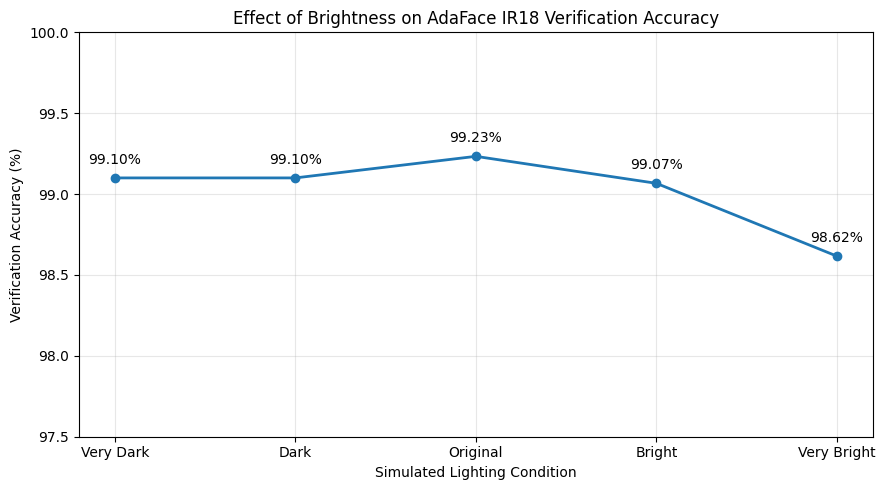

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    lighting_df["Condition"],
    lighting_df["Accuracy (%)"],
    marker="o",
    linewidth=2
)

for x, y in zip(
    lighting_df["Condition"],
    lighting_df["Accuracy (%)"]
):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.ylim(97.5, 100)
plt.xlabel("Simulated Lighting Condition")
plt.ylabel("Verification Accuracy (%)")
plt.title("Effect of Brightness on AdaFace IR18 Verification Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Effect of Image Quality

This experiment investigates how Gaussian blur affects the face verification performance of AdaFace IR18.

Different levels of blur are applied to the LFW facial images to simulate reductions in image sharpness and quality.

Verification accuracy and false rejection rates are measured to determine how increasing blur affects the model's ability to recognise matching faces.

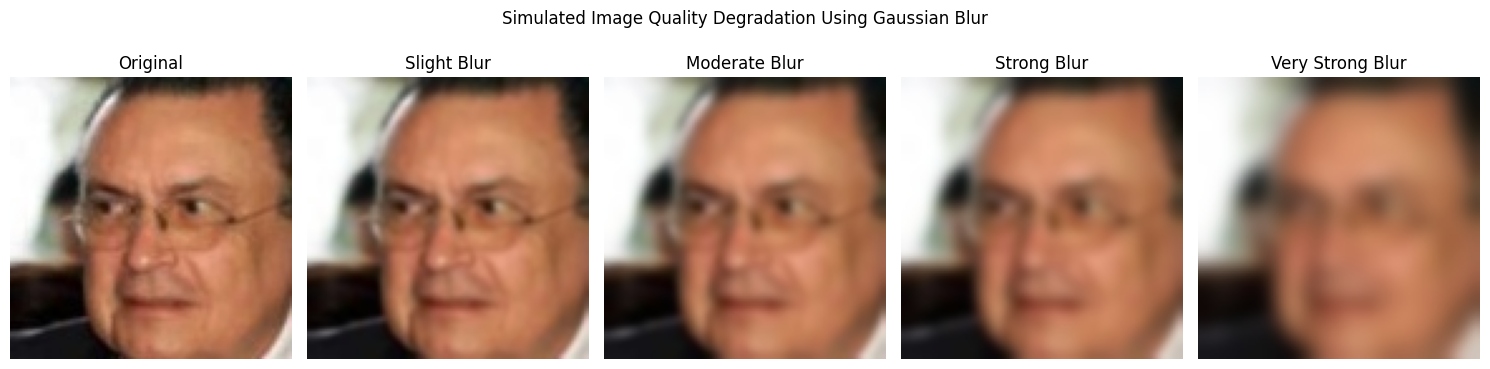

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Decode an LFW face image
image = cv2.imdecode(
    np.frombuffer(lfw_images[0], dtype=np.uint8),
    cv2.IMREAD_COLOR
)

# Different levels of Gaussian blur
blur_levels = {
    "Original": 0,
    "Slight Blur": 3,
    "Moderate Blur": 7,
    "Strong Blur": 11,
    "Very Strong Blur": 21
}

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, (name, kernel_size) in zip(axes, blur_levels.items()):

    if kernel_size == 0:
        modified = image.copy()
    else:
        modified = cv2.GaussianBlur(
            image,
            (kernel_size, kernel_size),
            0
        )

    ax.imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Simulated Image Quality Degradation Using Gaussian Blur")
plt.tight_layout()
plt.show()

In [18]:
import cv2
import numpy as np
import pandas as pd
import torch.nn.functional as F

# Keep reference images unchanged
reference_embeddings = F.normalize(
    lfw_embeddings[0::2], p=2, dim=1
)

comparison_images = lfw_images[1::2]

blur_results = []

for condition, kernel_size in blur_levels.items():
    print(f"Evaluating {condition}...")

    if kernel_size == 0:
        comparison_embeddings = lfw_embeddings[1::2]
    else:
        modified_images = []

        for image_bytes in comparison_images:
            image = cv2.imdecode(
                np.frombuffer(image_bytes, dtype=np.uint8),
                cv2.IMREAD_COLOR
            )

            modified = cv2.GaussianBlur(
                image,
                (kernel_size, kernel_size),
                0
            )

            success, encoded = cv2.imencode(".jpg", modified)

            if not success:
                raise ValueError("Image encoding failed")

            modified_images.append(encoded.tobytes())

        comparison_embeddings = get_embeddings(
            model, modified_images, batch_size=128
        )

    comparison_embeddings = F.normalize(
        comparison_embeddings, p=2, dim=1
    )

    scores = (
        reference_embeddings * comparison_embeddings
    ).sum(dim=1).numpy()

    metrics = evaluate(scores, lfw_labels)

    blur_results.append({
        "Condition": condition,
        "Kernel Size": kernel_size,
        "Accuracy (%)": metrics["accuracy"] * 100,
        "EER (%)": metrics["eer"] * 100,
        "TAR @ FAR 0.1%": metrics["tar"] * 100
    })

blur_df = pd.DataFrame(blur_results)

display(blur_df.round(2))

Evaluating Original...
Evaluating Slight Blur...
Evaluating Moderate Blur...
Evaluating Strong Blur...
Evaluating Very Strong Blur...


,Condition,Kernel Size,Accuracy (%),EER (%),TAR @ FAR 0.1%
0,Original,0,99.23,0.90,97.27
1,Slight Blur,3,99.07,0.87,97.57
2,Moderate Blur,7,98.88,1.25,97.00
3,Strong Blur,11,98.28,1.75,94.77
4,Very Strong Blur,21,92.53,7.50,62.57


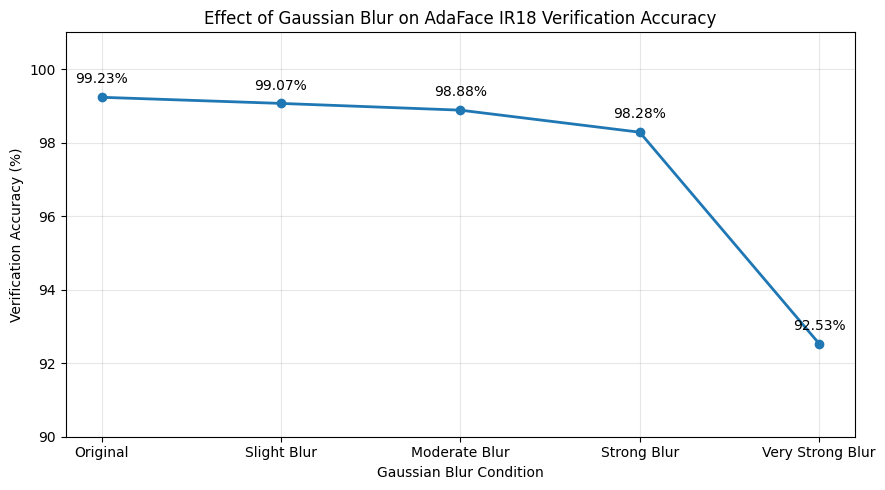

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    blur_df["Condition"],
    blur_df["Accuracy (%)"],
    marker="o",
    linewidth=2
)

for x, y in zip(
    blur_df["Condition"],
    blur_df["Accuracy (%)"]
):
    plt.annotate(
        f"{y:.2f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.ylim(90, 101)
plt.xlabel("Gaussian Blur Condition")
plt.ylabel("Verification Accuracy (%)")
plt.title("Effect of Gaussian Blur on AdaFace IR18 Verification Accuracy")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

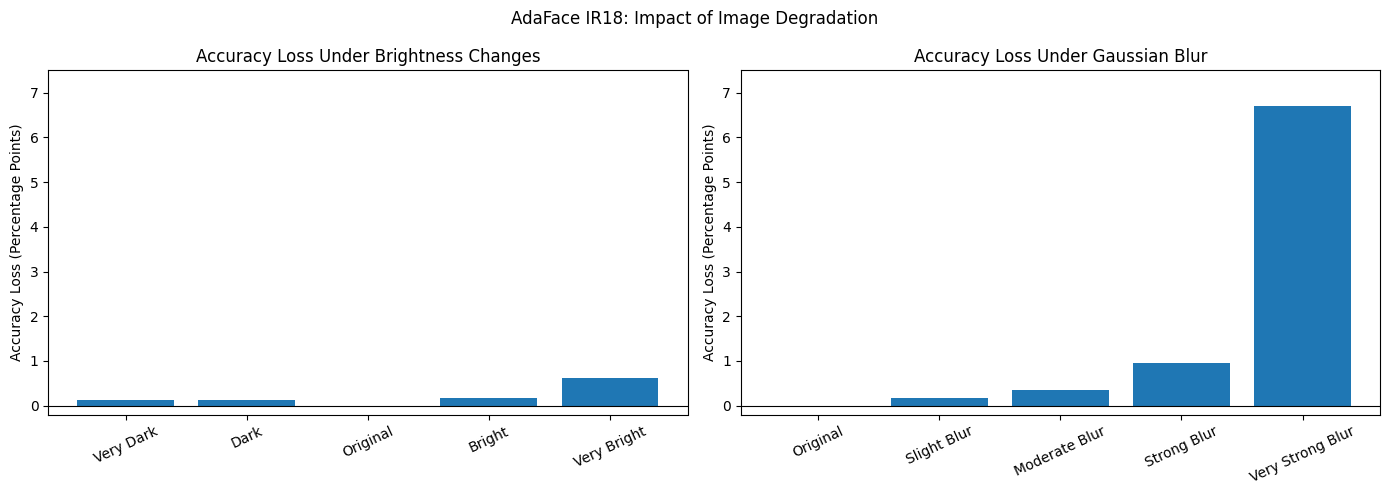

In [20]:
import matplotlib.pyplot as plt
import numpy as np

baseline = 99.23

lighting_drop = baseline - lighting_df["Accuracy (%)"]
blur_drop = baseline - blur_df["Accuracy (%)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Lighting experiment
axes[0].bar(
    lighting_df["Condition"],
    lighting_drop
)
axes[0].set_title("Accuracy Loss Under Brightness Changes")
axes[0].set_ylabel("Accuracy Loss (Percentage Points)")
axes[0].set_ylim(-0.2, 7.5)
axes[0].tick_params(axis="x", rotation=25)
axes[0].axhline(0, color="black", linewidth=0.8)

# Blur experiment
axes[1].bar(
    blur_df["Condition"],
    blur_drop
)
axes[1].set_title("Accuracy Loss Under Gaussian Blur")
axes[1].set_ylabel("Accuracy Loss (Percentage Points)")
axes[1].set_ylim(-0.2, 7.5)
axes[1].tick_params(axis="x", rotation=25)
axes[1].axhline(0, color="black", linewidth=0.8)

plt.suptitle("AdaFace IR18: Impact of Image Degradation")
plt.tight_layout()
plt.show()

In [21]:
import numpy as np

# Use the original LFW scores and labels
scores = np.asarray(lfw_scores)
labels = np.asarray(lfw_labels, dtype=bool)

# Use a fixed, reproducible 80/20 split
rng = np.random.default_rng(42)
indices = rng.permutation(len(scores))

train_idx = indices[:int(0.8 * len(scores))]
test_idx = indices[int(0.8 * len(scores)):]

# Find the best threshold using training pairs only
thresholds = np.linspace(-1, 1, 400)

train_accuracies = [
    np.mean((scores[train_idx] >= t) == labels[train_idx])
    for t in thresholds
]

fixed_threshold = thresholds[np.argmax(train_accuracies)]

# Evaluate on the untouched test pairs
test_accuracy = np.mean(
    (scores[test_idx] >= fixed_threshold) == labels[test_idx]
)

print("Fixed verification threshold:", round(fixed_threshold, 4))
print("Original LFW test accuracy:", f"{test_accuracy * 100:.2f}%")
print("Training pairs:", len(train_idx))
print("Test pairs:", len(test_idx))

Fixed verification threshold: 0.218
Original LFW test accuracy: 98.58%
Training pairs: 4800
Test pairs: 1200


In [22]:
fixed_lighting_results = []

for condition, factor in brightness_levels.items():
    print(f"Evaluating {condition}...")

    if factor == 1.0:
        test_scores = lfw_scores[test_idx]
    else:
        modified_images = []

        for pair_idx in test_idx:
            image_bytes = lfw_images[2 * pair_idx + 1]

            image = cv2.imdecode(
                np.frombuffer(image_bytes, dtype=np.uint8),
                cv2.IMREAD_COLOR
            )

            modified = np.clip(
                image.astype(np.float32) * factor,
                0, 255
            ).astype(np.uint8)

            success, encoded = cv2.imencode(".jpg", modified)

            if not success:
                raise ValueError("Image encoding failed")

            modified_images.append(encoded.tobytes())

        modified_embeddings = get_embeddings(
            model, modified_images, batch_size=128
        )

        modified_embeddings = F.normalize(
            modified_embeddings, p=2, dim=1
        )

        reference = F.normalize(
            lfw_embeddings[2 * test_idx], p=2, dim=1
        )

        test_scores = (
            reference * modified_embeddings
        ).sum(dim=1).numpy()

    predictions = test_scores >= fixed_threshold
    actual = lfw_labels[test_idx]

    accuracy = np.mean(predictions == actual)
    false_acceptance = np.mean(predictions[~actual])
    false_rejection = np.mean(~predictions[actual])

    fixed_lighting_results.append({
        "Condition": condition,
        "Accuracy (%)": accuracy * 100,
        "FAR (%)": false_acceptance * 100,
        "FRR (%)": false_rejection * 100
    })

fixed_lighting_df = pd.DataFrame(fixed_lighting_results)

display(fixed_lighting_df.round(2))


Evaluating Very Dark...
Evaluating Dark...
Evaluating Original...
Evaluating Bright...
Evaluating Very Bright...


,Condition,Accuracy (%),FAR (%),FRR (%)
0,Very Dark,98.67,0.83,1.85
1,Dark,98.83,1.16,1.18
2,Original,98.58,1.32,1.51
3,Bright,98.58,1.32,1.51
4,Very Bright,98.42,0.99,2.18


In [23]:
fixed_blur_results = []

reference = F.normalize(
    lfw_embeddings[2 * test_idx], p=2, dim=1
)

actual = lfw_labels[test_idx]

for condition, kernel_size in blur_levels.items():
    print(f"Evaluating {condition}...")

    if kernel_size == 0:
        test_scores = lfw_scores[test_idx]
    else:
        modified_images = []

        for pair_idx in test_idx:
            image_bytes = lfw_images[2 * pair_idx + 1]

            image = cv2.imdecode(
                np.frombuffer(image_bytes, dtype=np.uint8),
                cv2.IMREAD_COLOR
            )

            modified = cv2.GaussianBlur(
                image,
                (kernel_size, kernel_size),
                0
            )

            success, encoded = cv2.imencode(".jpg", modified)

            if not success:
                raise ValueError("Image encoding failed")

            modified_images.append(encoded.tobytes())

        modified_embeddings = get_embeddings(
            model, modified_images, batch_size=128
        )

        modified_embeddings = F.normalize(
            modified_embeddings, p=2, dim=1
        )

        test_scores = (
            reference * modified_embeddings
        ).sum(dim=1).numpy()

    predictions = test_scores >= fixed_threshold

    accuracy = np.mean(predictions == actual)
    false_acceptance = np.mean(predictions[~actual])
    false_rejection = np.mean(~predictions[actual])

    fixed_blur_results.append({
        "Condition": condition,
        "Accuracy (%)": accuracy * 100,
        "FAR (%)": false_acceptance * 100,
        "FRR (%)": false_rejection * 100
    })

fixed_blur_df = pd.DataFrame(fixed_blur_results)

display(fixed_blur_df.round(2))


Evaluating Original...
Evaluating Slight Blur...
Evaluating Moderate Blur...
Evaluating Strong Blur...
Evaluating Very Strong Blur...


,Condition,Accuracy (%),FAR (%),FRR (%)
0,Original,98.58,1.32,1.51
1,Slight Blur,98.50,1.49,1.51
2,Moderate Blur,98.42,1.32,1.85
3,Strong Blur,97.67,1.49,3.19
4,Very Strong Blur,82.42,0.00,35.46


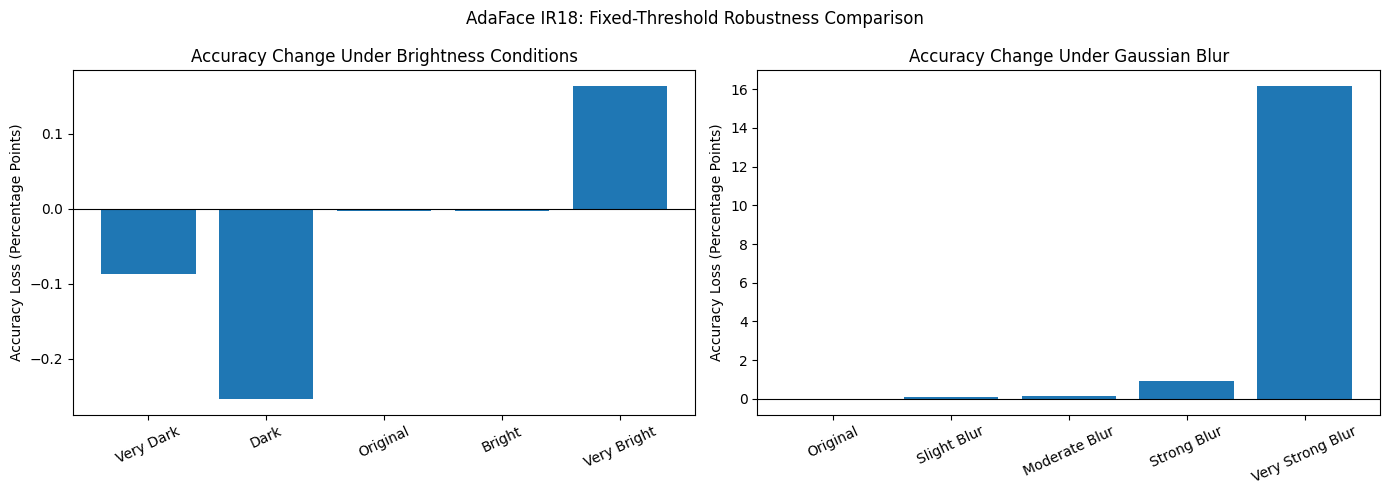

In [24]:
import matplotlib.pyplot as plt

baseline = 98.58

lighting_loss = baseline - fixed_lighting_df["Accuracy (%)"]
blur_loss = baseline - fixed_blur_df["Accuracy (%)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    fixed_lighting_df["Condition"],
    lighting_loss
)
axes[0].set_title("Accuracy Change Under Brightness Conditions")
axes[0].set_ylabel("Accuracy Loss (Percentage Points)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].axhline(0, color="black", linewidth=0.8)

axes[1].bar(
    fixed_blur_df["Condition"],
    blur_loss
)
axes[1].set_title("Accuracy Change Under Gaussian Blur")
axes[1].set_ylabel("Accuracy Loss (Percentage Points)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].axhline(0, color="black", linewidth=0.8)

plt.suptitle("AdaFace IR18: Fixed-Threshold Robustness Comparison")
plt.tight_layout()
plt.show()



## 8. Experimental Findings

### Baseline Performance
The AdaFace IR18 model achieved 99.23% verification accuracy on the LFW benchmark using 10-fold cross-validation.

For the robustness experiments, a fixed verification threshold of 0.2180 was selected using 4,800 training pairs and evaluated on 1,200 held-out test pairs. The baseline test accuracy was 98.58%.

### Effect of Lighting Conditions
Simulated brightness changes had a relatively small effect on face verification performance. Accuracy ranged from 98.62% under very bright conditions to 99.23% for the original images. The largest reduction was 0.61 percentage points, suggesting that AdaFace IR18 was relatively robust to the brightness transformations tested.

### Effect of Image Quality
Gaussian blur produced a reduction in face verification accuracy as image quality deteriorated. Accuracy decreased from 99.23% for the original images to 92.53% under very strong blur, representing a reduction of 6.70 percentage points. This suggests that AdaFace IR18 becomes less reliable when facial images experience severe blurring.

### Comparison
The results suggest that severe image degradation through Gaussian blur has a greater negative effect on AdaFace IR18 verification performance than the simulated brightness changes tested.

### Limitations
These experiments used artificial brightness and blur transformations rather than naturally occurring environmental conditions. The findings are specific to the pretrained AdaFace IR18 model, the LFW dataset, and the experimental setup.


In [25]:
# Compare AdaFace IR18 against a majority-class baseline
# Both methods are evaluated on the same 1,200 held-out LFW pairs.

import numpy as np
import pandas as pd

# Get training and test labels
train_labels = np.asarray(lfw_labels, dtype=bool)[train_idx]
test_labels = np.asarray(lfw_labels, dtype=bool)[test_idx]

# Determine the majority class using training data only
majority_class = np.mean(train_labels) >= 0.5

# Evaluate the majority-class baseline
baseline_accuracy = np.mean(test_labels == majority_class) * 100

# AdaFace accuracy from the fixed-threshold experiment
adaface_accuracy = test_accuracy * 100

# Compare both methods
fair_comparison_df = pd.DataFrame({
    "Method": ["Majority-Class Baseline", "AdaFace IR18"],
    "Test Accuracy (%)": [baseline_accuracy, adaface_accuracy]
})

display(fair_comparison_df.round(2))


,Method,Test Accuracy (%)
0,Majority-Class Baseline,49.58
1,AdaFace IR18,98.58


## 9. Conclusion

This investigation evaluated the performance and robustness of the pretrained AdaFace IR18 model for facial recognition and biometric authentication.

The model achieved 99.23% verification accuracy on the LFW benchmark dataset, demonstrating strong performance under standard evaluation conditions. However, performance varied across the six benchmark datasets, with lower accuracy on datasets containing more challenging facial variations.

The robustness experiments demonstrated that changes in brightness had a relatively small effect on verification accuracy, whereas Gaussian blur caused a more substantial reduction. Under very strong blur, cross-validation accuracy decreased from 99.23% to 92.53%. In the separate fixed-threshold experiment, accuracy decreased from 98.58% to 82.42%, while the false rejection rate increased to 35.46%. These findings suggest that severe image degradation can significantly affect face verification reliability.

Overall, the findings indicate that AdaFace IR18 performs well under favourable image conditions but remains sensitive to substantial image degradation. Future work could investigate variations in facial pose, natural lighting conditions and alternative face recognition models to assess whether these findings generalise.